In [105]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [106]:
df = pd.read_csv(r"C:\Users\User\Downloads\bankloan.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0.0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1.0,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0.0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [107]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    float64
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(5), int64(1), object(7)
memory usage: 62.5+ KB


## Explanation:

Displays the data type of each column.


1. Loan_ID, Gender, Married, Education, Self_Employed, Property_Area, Loan_Status are object (categorical/text).

2. Dependents, ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term, Credit_History are numeric (float64 or int64).

In [108]:
df.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,Female,No,0.0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3.0,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1.0,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2.0,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,Female,No,0.0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


In [109]:
df.dtypes

Loan_ID               object
Gender                object
Married               object
Dependents           float64
Education             object
Self_Employed         object
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area         object
Loan_Status           object
dtype: object

In [110]:
df.describe()

,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,599.000000,614.000000,614.000000,592.000000,600.00000,564.000000
mean,0.762938,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,1.015216,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,0.000000,150.000000,0.000000,9.000000,12.00000,0.000000
25%,0.000000,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,0.000000,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,2.000000,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,3.000000,81000.000000,41667.000000,700.000000,480.00000,1.000000


## Explanation:

Generates descriptive statistics for numerical columns:
- Dependents: mean ≈ 0.76, max = 3
- ApplicantIncome: mean ≈ 5403, max = 81000
- CoapplicantIncome: mean ≈ 1621, max = 41667
- LoanAmount: mean ≈ 146.4, max = 700

In [111]:
df.shape # The dataset has 614 rows and 13 columns.

(614, 13)

In [112]:
df["Gender"].describe()

count      601
unique       2
top       Male
freq       489
Name: Gender, dtype: object

In [113]:
df["ApplicantIncome"].describe()

count      614.000000
mean      5403.459283
std       6109.041673
min        150.000000
25%       2877.500000
50%       3812.500000
75%       5795.000000
max      81000.000000
Name: ApplicantIncome, dtype: float64

<Axes: xlabel='Gender', ylabel='ApplicantIncome'>

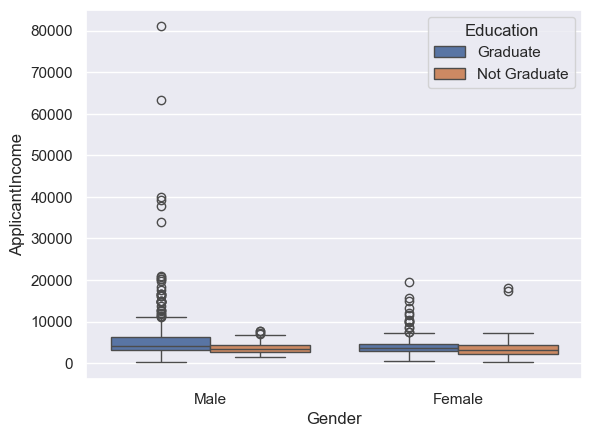

In [114]:
sns.boxplot(data = df, y = "ApplicantIncome", x ="Gender", hue = 'Education')



## Explanations
- This boxplot reveals a dataset with highly skewed income distributions:

- Low Median Incomes: The vast majority of applicants in all demographics earn relatively low amounts (under 10,000).

- "Ceiling" Effect: There appears to be a ceiling for female income in this dataset, with very few breaking past 20,000, regardless of education.

- The Male Graduate Advantage: While the typical male graduate doesn't earn drastically more than anyone else, male graduates are the only group with significant access to extreme high-income brackets (30,000 to 80,000+).

<Axes: >

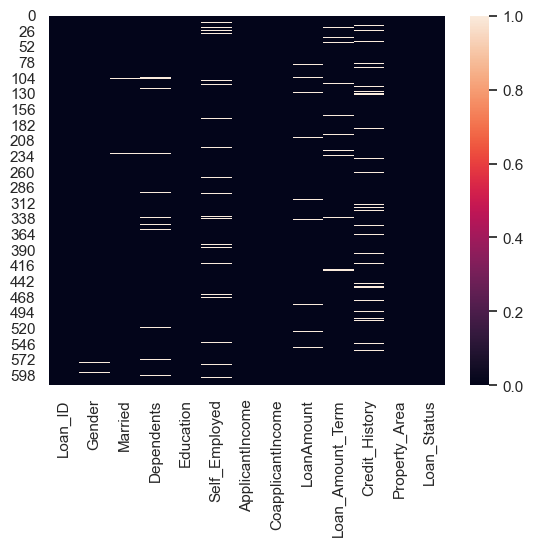

In [115]:
sns.heatmap(df.isnull())

## Explanation:

Visualizes missing values across the dataset.

- Yellow/light lines indicate missing data.

- Missing values are present in Gender, Married, Dependents, Self_Employed, LoanAmount, Loan_Amount_Term, and Credit_History.



In [116]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

The heatmap shows missing values distributed across rows.

- Columns like Loan_ID, Education, ApplicantIncome, CoapplicantIncome, Property_Area, and Loan_Status have no missing values.

- Other columns have varying degrees of missingness.

In [117]:
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])

df["Married"] = df["Married"].fillna(df["Married"].mode()[0])

df["Dependents"] = df["Dependents"].fillna(df["Dependents"].mode()[0])

df["Self_Employed"] = df["Self_Employed"].fillna(df["Self_Employed"].mode()[0])

In [118]:
df["LoanAmount"] = df["LoanAmount"].fillna(df["LoanAmount"].mean())

df["Loan_Amount_Term"] = df["Loan_Amount_Term"].fillna(df["Loan_Amount_Term"].mean())

df["Credit_History"] = df["Credit_History"].fillna(df["Credit_History"].mode()[0])

Explanation:
Imputes missing values:

- Categorical columns (Self_Employed, Credit_History): filled with the mode (most frequent value).

- Numerical columns (LoanAmount, Loan_Amount_Term): filled with the mean.

In [119]:
df.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

<Axes: >

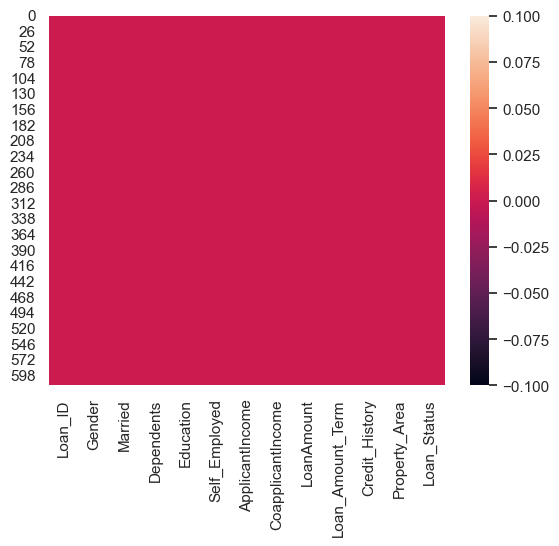

In [120]:
sns.heatmap(df.isnull())

Explanation: The heatmap now shows no missing values (uniform color).



Explanation:
Displays the first 8 columns of the dataset (Loan_ID to ApplicantIncome) for the first 5 rows

In [122]:
df.pivot_table(index = ["Education" ,"Married", "Gender"], values = [ "ApplicantIncome","LoanAmount","Loan_Amount_Term"],aggfunc =["sum","count","mean","max","min"])

sum                                 \
                            ApplicantIncome    LoanAmount Loan_Amount_Term   
Education    Married Gender                                                  
Graduate     No      Female          286255   7820.412162          23358.0   
                     Male            583057  14934.648649          36222.0   
             Yes     Female          141220   4159.412162           8904.0   
                     Male           1801036  46919.709459          96936.0   
Not Graduate No      Female           74048   1529.412162           5004.0   
                     Male            115332   3290.412162          10158.0   
             Yes     Female           18546    740.000000           2160.0   
                     Male            298230  10503.060811          27246.0   

                                      count                              \
                            ApplicantIncome LoanAmount Loan_Amount_Term   
Education    Married Gender                                               
Graduate     No      Female              66         66               66   
                     Male               102        102              102   
             Yes     Female              26         26               26   
                     Male               286        286              286   
Not Graduate No      Female              14         14               14   
                     Male                31         31               31   
             Yes     Female               6          6                6   
                     Male                83         83               83   

                                       mean                               \
                            ApplicantIncome  LoanAmount Loan_Amount_Term   
Education    Married Gender                                                
Graduate     No      Female     4337.196970  118.491093       353.909091   
                     Male       5716.245098  146.418124       355.117647   
             Yes     Female     5431.538462  159.977391       342.461538   
                     Male       6297.328671  164.054928       338.937063   
Not Graduate No      Female     5289.142857  109.243726       357.428571   
                     Male       3720.387097  106.142328       327.677419   
             Yes     Female     3091.000000  123.333333       360.000000   
                     Male       3593.132530  126.542901       328.265060   

                                        max                              \
                            ApplicantIncome LoanAmount Loan_Amount_Term   
Education    Married Gender                                               
Graduate     No      Female           15759      350.0            480.0   
                     Male             37719      650.0            480.0   
             Yes     Female           19484      600.0            480.0   
                     Male             81000      700.0            480.0   
Not Graduate No      Female           18165      225.0            360.0   
                     Male              7333      190.0            480.0   
             Yes     Female            7142      178.0            360.0   
                     Male              7667      279.0            480.0   

                                        min                              
                            ApplicantIncome LoanAmount Loan_Amount_Term  
Education    Married Gender                                              
Graduate     No      Female             416        9.0             36.0  
                     Male              1800       47.0             60.0  
             Yes     Female            1378       36.0             84.0  
                     Male               150       17.0             12.0  
Not Graduate No      Female            1830       53.0            342.0  
                     Male              1442       25.0             36.0  
             Yes     Femal

## Explanation:

- Creates a pivot table summarizing total ApplicantIncome, CoapplicantIncome, and LoanAmount grouped by Education, Married, and Gender.

In [123]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0.0,Graduate,No,5849,0.0,146.412162,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1.0,Graduate,No,4583,1508.0,128.000000,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.000000,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.000000,360.0,1.0,Urban,Y
4,LP001008,Male,No,0.0,Graduate,No,6000,0.0,141.000000,360.0,1.0,Urban,Y


In [124]:

def  analyze_ApplicantIncome(df):
    total_applicant_income = df["ApplicantIncome"].sum()
    maximum_applicant_income = df["ApplicantIncome"].max()
    minimum_applicant_income = df["ApplicantIncome"].min()
    average_applicant_income = df["ApplicantIncome"].mean()
    
    return (total_applicant_income,maximum_applicant_income, minimum_applicant_income,average_applicant_income)


total_applicant_income,maximum_applicant_income, minimum_applicant_income,average_applicant_income = analyze_ApplicantIncome(df)
print(":::::::::::::::::::::::::APPLICANT INCOME ANALYSIS REPORT:::::::::::::::::::::::::::: ")
print(f"Total_Applicant_Income      : {total_applicant_income:,.5f} ")
print(f"Maximum_Applicant_Income    : {maximum_applicant_income:.5f} ")
print(f"Minimum_Applicant_Income    : {minimum_applicant_income:.5f} ")
print(f"average_Applicant_Income    : {average_applicant_income:5f} ")


print("::::::::::::::::::::::::::End:::::::::::::::::::::::::::::::::::::::::::::::::")

:::::::::::::::::::::::::APPLICANT INCOME ANALYSIS REPORT:::::::::::::::::::::::::::: 
Total_Applicant_Income      : 3,317,724.00000 
Maximum_Applicant_Income    : 81000.00000 
Minimum_Applicant_Income    : 150.00000 
average_Applicant_Income    : 5403.459283 
::::::::::::::::::::::::::End:::::::::::::::::::::::::::::::::::::::::::::::::


In [125]:

def  analyze_Loan_Amount(df):
    total_loan_amount = df["LoanAmount"].sum()
    maximum_loan_amount = df["LoanAmount"].max()
    minimum_loan_amount = df["LoanAmount"].min()
    average_loan_amount = df["LoanAmount"].mean()
    
    return (total_loan_amount,maximum_loan_amount, minimum_loan_amount,average_loan_amount)


total_loan_amount,maximum_loan_amount, minimum_loan_amount,average_loan_amount = analyze_Loan_Amount(df)
print(":::::::::::::::::::::::::APPLICANT INCOME ANALYSIS REPORT:::::::::::::::::::::::::::: ")
print(f"Total_Loan_Amount        : {total_loan_amount:,.5f} ")
print(f"Maximum_Loan_Amount      : {maximum_loan_amount:.5f} ")
print(f"Minimum_Loan_Amount      : {minimum_loan_amount:.5f} ")
print(f"average_Loan_Amount      : {average_loan_amount:5f} ")


print("::::::::::::::::::::::::::End:::::::::::::::::::::::::::::::::::::::::::::::::")

:::::::::::::::::::::::::APPLICANT INCOME ANALYSIS REPORT:::::::::::::::::::::::::::: 
Total_Loan_Amount        : 89,897.06757 
Maximum_Loan_Amount      : 700.00000 
Minimum_Loan_Amount      : 9.00000 
average_Loan_Amount      : 146.412162 
::::::::::::::::::::::::::End:::::::::::::::::::::::::::::::::::::::::::::::::


In [126]:
df.drop_duplicates(inplace = True)
df[df.duplicated()]

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status


Explanation:

- Removes duplicate rows (if any) and then checks for remaining duplicates. The output shows an empty DataFrame, meaning no duplicates exist.

::::::::::::::::::::::::::::::: EDA (EXPLANATORY DATA ANALYSIS VIA PLOTS):::::::::::::::::::::::::::::::::::::::::

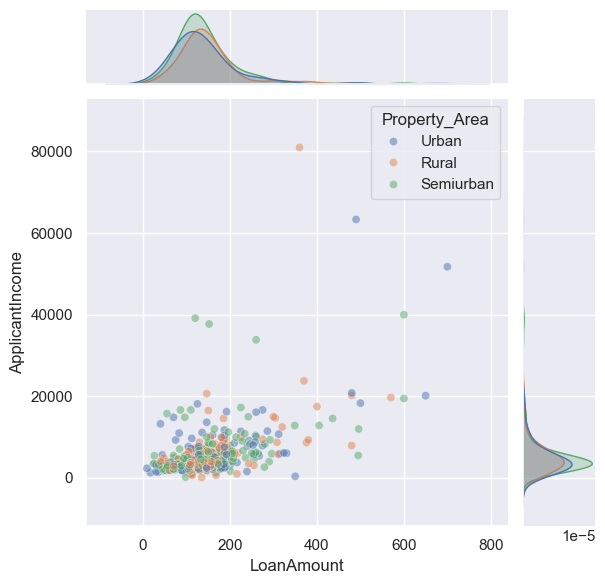

In [127]:
sns.jointplot(x = "LoanAmount", y = "ApplicantIncome", hue = "Property_Area", data =df, alpha = 0.5)

## Explanation:

- Creates a jointplot showing the relationship between LoanAmount and ApplicantIncome, colored by Property_Area (Urban, Rural, Semiurban).

- Most applicants have lower incomes and loan amounts.

- A few high-income outliers exist across all property areas.

## The jointplot reveals:

- A dense cluster of applicants with incomes below 20,000 and loan amounts below 200.

- Outliers with high income (up to 80,000) and high loan amounts (up to 700).

- Property areas are mixed within the main cluster.



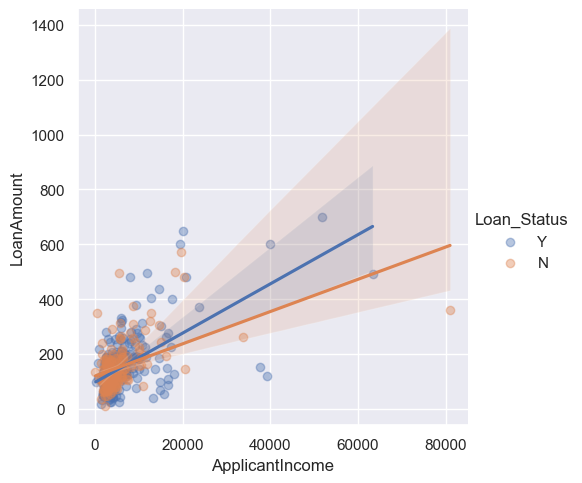

In [128]:
sns.lmplot(
    y = "LoanAmount",
    x = "ApplicantIncome",
    data = df,
    scatter_kws={"alpha" : 0.4},
    hue = "Loan_Status",
    
)

## Explanation:

- Creates a scatter plot with a linear regression line, colored by Loan_Status (Y/N).

- Shows the relationship between income and loan amount.

- Helps visualize whether loan approval correlates with income/loan amount.

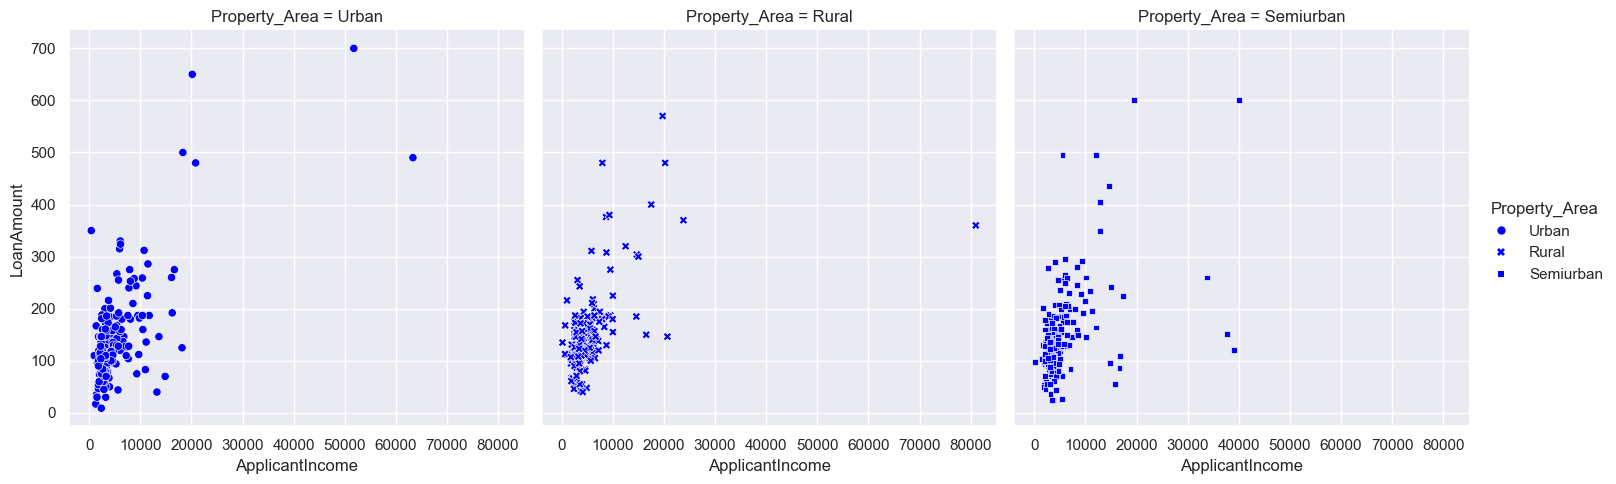

In [129]:
sns.relplot(data = df, x ="ApplicantIncome", y = 'LoanAmount', style = 'Property_Area',color = 'blue', col = 'Property_Area', col_wrap = 3)

## Explanation:

1. Creates faceted scatter plots for each Property_Area (Urban, Rural, Semiurban).

- Each subplot shows the income vs. loan amount relationship.

- Allows comparison of patterns across different property areas

<Axes: xlabel='ApplicantIncome', ylabel='LoanAmount'>

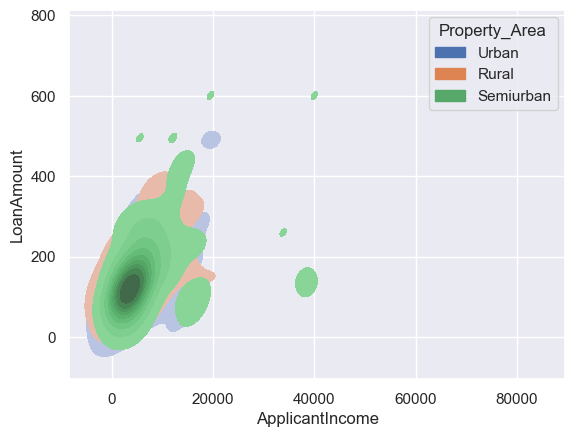

In [130]:
sns.kdeplot(data = df, x ="ApplicantIncome", y = 'LoanAmount', fill = True , hue = 'Property_Area')

<Axes: xlabel='ApplicantIncome', ylabel='LoanAmount'>

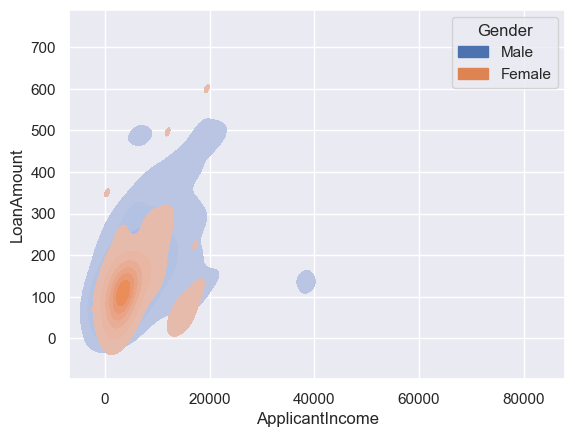

In [131]:
sns.kdeplot(data = df, x ="ApplicantIncome", y = 'LoanAmount', fill = True , hue = 'Gender')

## Explanation:

- Creates a bivariate KDE (Kernel Density Estimate) plot showing the joint distribution of ApplicantIncome and LoanAmount, colored by Gender.

- Male applicants (blue) show a wider spread.

- Female applicants (orange) are concentrated in lower income/loan ranges.

<Axes: xlabel='ApplicantIncome', ylabel='LoanAmount'>

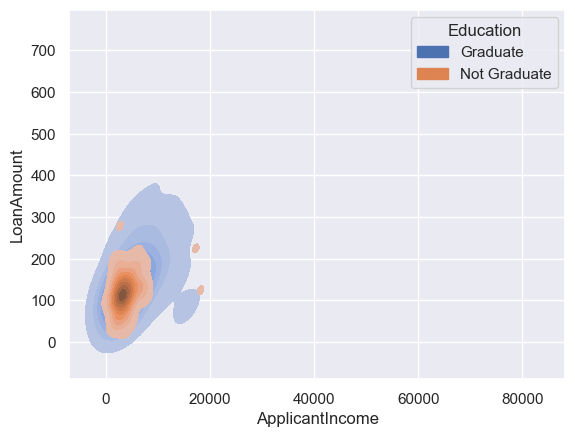

In [132]:
sns.kdeplot(data = df, x ="ApplicantIncome", y = 'LoanAmount', fill = True , hue = 'Education')

## Explanation:

- Bivariate KDE plot colored by Education (Graduate vs. Not Graduate).

- Graduates (blue) show a wider distribution.

- Non-graduates (orange) are more concentrated in lower ranges.

<Axes: xlabel='ApplicantIncome', ylabel='LoanAmount'>

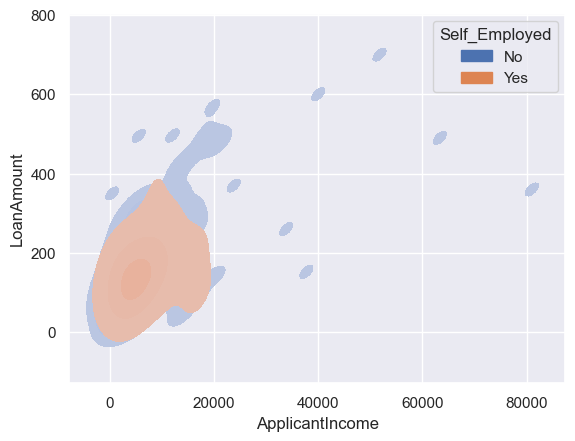

In [133]:
sns.kdeplot(data = df, x ="ApplicantIncome", y = 'LoanAmount', fill = True , hue = 'Self_Employed')

<Axes: xlabel='ApplicantIncome', ylabel='LoanAmount'>

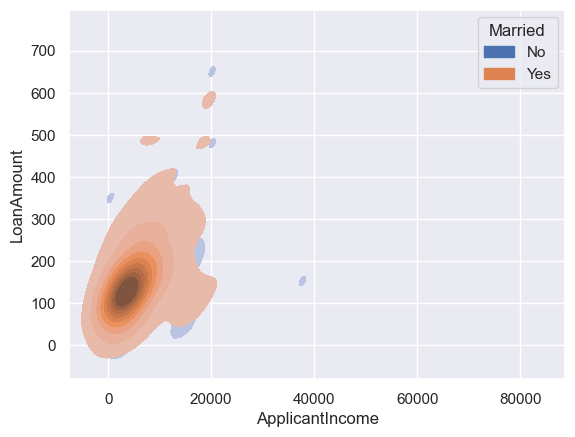

In [134]:
 	sns.kdeplot(data = df, x ="ApplicantIncome", y = 'LoanAmount', fill = True , hue = 'Married')

## Explanation:

- Bivariate KDE plot colored by Married status (Yes/No).

- Married applicants (orange) show a broader distribution.

- Unmarried applicants (blue) are more concentrated.



<Axes: xlabel='LoanAmount', ylabel='Gender'>

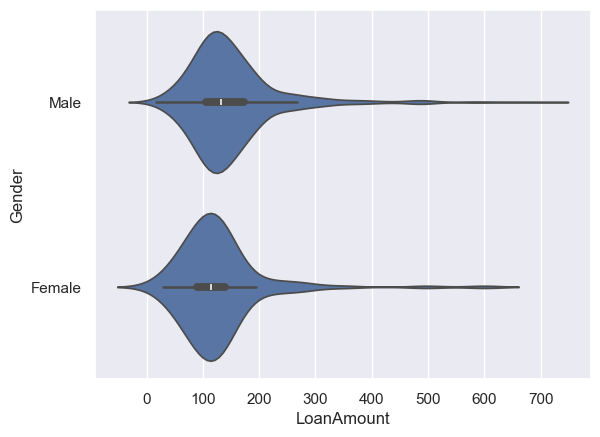

In [135]:
sns.violinplot(data = df, x ='LoanAmount', y = 'Gender')

## Explanation:

- Creates a violin plot showing the distribution of LoanAmount by Gender.

- Both genders have similar median loan amounts (~120–140).

- Male applicants show a wider spread and more high-value outliers.

<Axes: xlabel='LoanAmount', ylabel='Gender'>

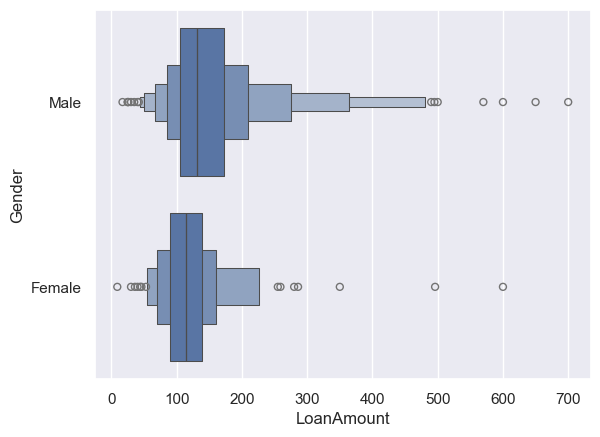

In [136]:
sns.boxenplot(data = df, x ='LoanAmount', y = 'Gender')


## Explanation:

Creates a boxen plot (letter-value plot) showing more detailed quantiles of LoanAmount by Gender


UNSUPERVISED MACHINE LEARNING WITH MULTIPLE PLOTS


In [137]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0.0,Graduate,No,5849,0.0,146.412162,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1.0,Graduate,No,4583,1508.0,128.000000,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.000000,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.000000,360.0,1.0,Urban,Y
4,LP001008,Male,No,0.0,Graduate,No,6000,0.0,141.000000,360.0,1.0,Urban,Y


In [138]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

c:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


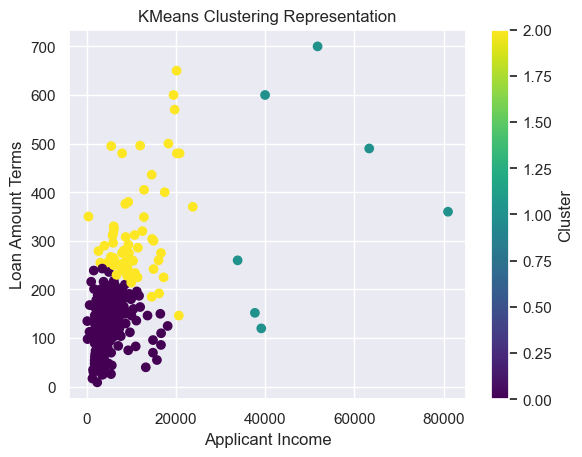

In [139]:
X = df[["ApplicantIncome","LoanAmount"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

model = KMeans(n_clusters = 3,
              n_init =10,
              random_state = 42)
model.fit(X_scaled)
clusters = model.fit_predict(X_scaled)
df["Clusters"] = clusters

plt.scatter(df["ApplicantIncome"],
           df["LoanAmount"],
           c = df["Clusters"],
           cmap = "viridis")
plt.title("KMeans Clustering Representation")
plt.xlabel("Applicant Income")
plt.ylabel("Loan Amount Terms")
plt.colorbar(label = "Cluster")
plt.show()

In [140]:
df["Clusters"].unique()

array([0, 2, 1], dtype=int32)

In [141]:
df.groupby("Clusters").agg({
    "ApplicantIncome" : ["mean","max","min", "std","count", "sum"],
    "LoanAmount" :["mean","max","min", "std","count", "sum"]
    
    
})


ApplicantIncome                                             \
                    mean    max    min           std count      sum   
Clusters                                                              
0            4222.983486  18165    150   2418.516644   545  2301526   
1           49544.428571  81000  33846  17176.113296     7   346811   
2           10796.564516  23803    416   5315.545240    62   669387   

          LoanAmount                                                     
                mean    max         min         std count           sum  
Clusters                                                                 
0         124.028726  243.0    9.000000   40.708048   545  67595.655405  
1         383.142857  700.0  120.000000  222.566416     7   2682.000000  
2         316.442132  650.0  146.412162  105.014356    62  19619.412162

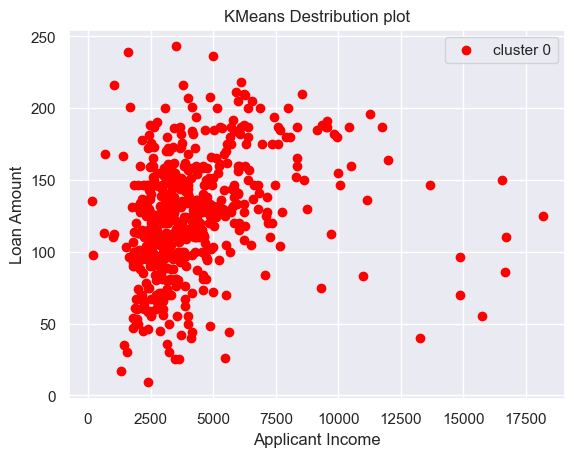

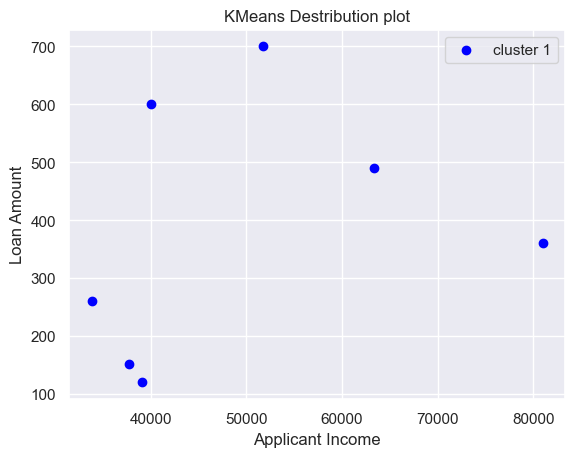

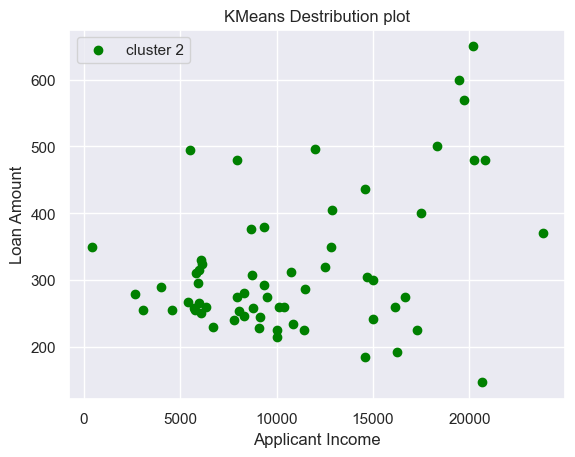

In [142]:
colors = ["red", "blue", "green"]
for cluster in range(3):
    data = df[df["Clusters"] == cluster]
    plt.scatter(
        data["ApplicantIncome"],
        data["LoanAmount"],
        color = colors[cluster],
        label =f"cluster {cluster}"
    )
    plt.xlabel("Applicant Income")
    plt.ylabel("Loan Amount")
    plt.title("KMeans Destribution plot")
    plt.legend()
    plt.show()


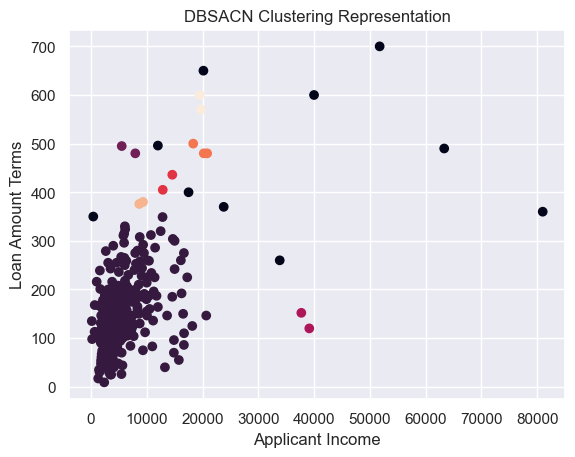

In [143]:
from sklearn.cluster import DBSCAN
dbscan =DBSCAN(eps = 0.5,
              min_samples = 2)
dbscan.fit(X_scaled)

df["Dbscan"]= dbscan.fit_predict(X_scaled)

plt.scatter(df["ApplicantIncome"],
           df["LoanAmount"],
           c = df["Dbscan"])
plt.title("DBSACN Clustering Representation")
plt.xlabel("Applicant Income")
plt.ylabel("Loan Amount Terms")
plt.show()



In [144]:
dbscan.labels_

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0, -1,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0, -1,  0,  0,  0,  0,  0,  1,  0,  0,  0,  0,  0, -1,  0,  2,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0

In [145]:
df["Dbscan"].unique()

array([ 0, -1,  1,  2,  3,  4,  5,  6])

In [146]:
df.groupby("Dbscan").agg({
    "ApplicantIncome" : ["mean","max","min", "std","count", "sum"],
    "LoanAmount" :["mean","max","min", "std","count", "sum", ]
    
})

ApplicantIncome                                             LoanAmount  \
                  mean    max    min           std count      sum        mean   
Dbscan                                                                          
-1        34383.000000  81000    416  24942.649743    10   343830  467.600000   
 0         4635.368866  20667    150   2953.648426   591  2739503  134.935817   
 1         6732.000000   7948   5516   1719.683692     2    13464  487.500000   
 2        38433.000000  39147  37719   1009.748484     2    76866  136.000000   
 3        13729.500000  14583  12876   1207.031275     2    27459  420.500000   
 4        19799.666667  20833  18333   1305.118130     3    59399  486.666667   
 5         8994.500000   9323   8666    464.569155     2    17989  378.000000   
 6        19607.000000  19730  19484    173.948268     2    39214  585.000000   

                                                      
          max    min         std count           sum  
Dbscan                                                
-1      700.0  260.0  144.805770    10   4676.000000  
 0      349.0    9.0   55.337697   591  79747.067568  
 1      495.0  480.0   10.606602     2    975.000000  
 2      152.0  120.0   22.627417     2    272.000000  
 3      436.0  405.0   21.920310     2    841.000000  
 4      500.0  480.0   11.547005     3   1460.000000  
 5      380.0  376.0    2.828427     2    756.000000  
 6      600.0  570.0   21.213203     2   1170.000000

In [147]:
from sklearn.decomposition import PCA
pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X_scaled)
X_pca

array([[ 0.05161231,  0.05161231],
       [-0.25009325,  0.06000604],
       [-0.95557586,  0.39873303],
       ...,
       [ 1.20670995, -0.58845203],
       [ 0.59427426, -0.08930976],
       [-0.20798803,  0.01790082]], shape=(614, 2))

In [148]:
df["PCA1"] = X_pca[:, 0]
df["PCA2"] = X_pca[:, 1]



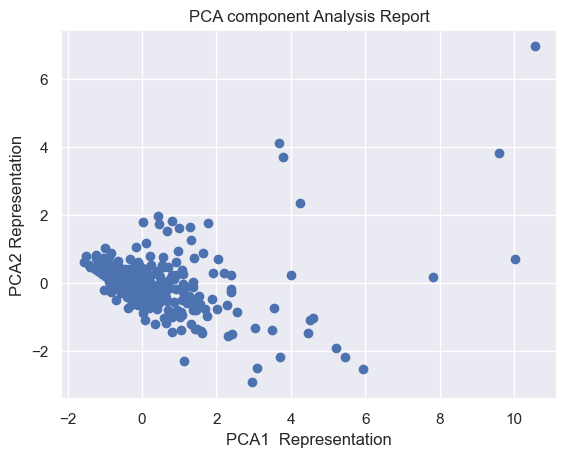

In [149]:
plt.scatter(df["PCA1"],
           df["PCA2"])
           
plt.xlabel("PCA1  Representation")
plt.ylabel("PCA2 Representation")
plt.title("PCA component Analysis Report")

plt.show()

In [150]:
pca.explained_variance_ratio_.sum()

np.float64(1.0)

c:\Users\User\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


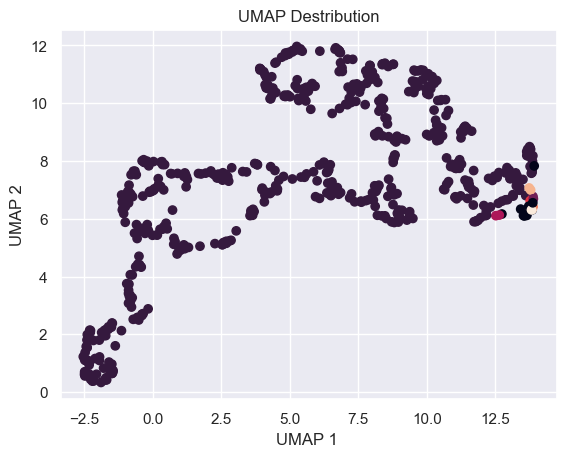

In [151]:
import umap.umap_ as umap
reducer = umap.UMAP(n_components = 2, random_state = 42)
embeding= reducer.fit_transform(X_scaled)
plt.scatter(embeding[:, 0],
           embeding[:,1],
         c = df["Dbscan"])
plt.xlabel("UMAP 1 ")
plt.ylabel("UMAP 2")
plt.title("UMAP Destribution")
plt.show()


In [152]:
df.head()


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Clusters,Dbscan,PCA1,PCA2
0,LP001002,Male,No,0.0,Graduate,No,5849,0.0,146.412162,360.0,1.0,Urban,Y,0,0,0.051612,0.051612
1,LP001003,Male,Yes,1.0,Graduate,No,4583,1508.0,128.000000,360.0,1.0,Rural,N,0,0,-0.250093,0.060006
2,LP001005,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.000000,360.0,1.0,Urban,Y,0,0,-0.955576,0.398733
3,LP001006,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.000000,360.0,1.0,Urban,Y,0,0,-0.549146,-0.104309
4,LP001008,Male,No,0.0,Graduate,No,6000,0.0,141.000000,360.0,1.0,Urban,Y,0,0,0.023528,0.114681


c:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


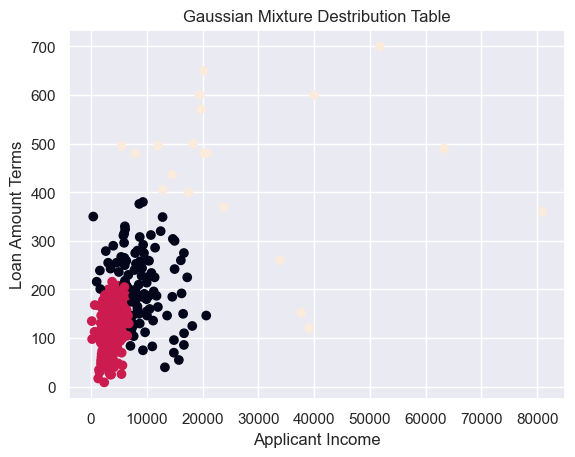

In [153]:
from sklearn.mixture import GaussianMixture
gaussian = GaussianMixture( n_components = 3, random_state = 42)
gaussian.fit(X_scaled)
cluster = gaussian.fit_predict(X_scaled)
df["Gaussian"] = cluster
plt.scatter(df["ApplicantIncome"],
           df["LoanAmount"],
           c = df["Gaussian"] )
plt.xlabel("Applicant Income")
plt.ylabel("Loan Amount Terms")
plt.title("Gaussian Mixture Destribution Table")
plt.show()

   

In [154]:
df.groupby("Gaussian").agg({
    "ApplicantIncome" : ["mean","max","min", "std","count", "sum"],
    "LoanAmount" :["mean","max","min", "std","count", "sum", ]
    
})

ApplicantIncome                                            \
                    mean    max   min           std count      sum   
Gaussian                                                             
0            9113.780702  20667   416   3798.140087   114  1038971   
1            3581.118750   6822   150   1253.959420   480  1718937   
2           27990.800000  81000  5516  19367.508256    20   559816   

          LoanAmount                                                
                mean    max    min         std count           sum  
Gaussian                                                            
0         207.312707  380.0   40.0   72.037257   114  23633.648649  
1         119.207123  216.0    9.0   37.367137   480  57219.418919  
2         452.200000  700.0  120.0  149.696043    20   9044.000000

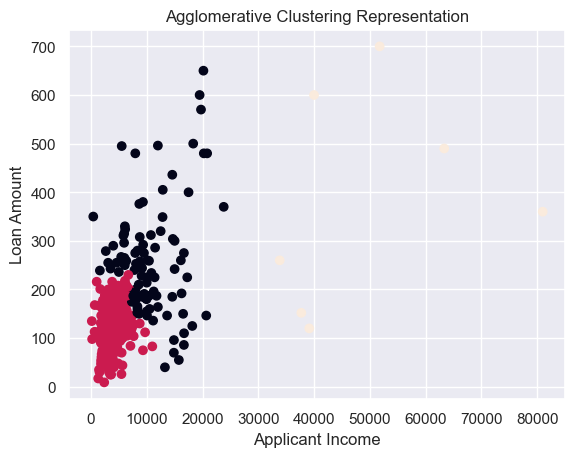

In [155]:
from sklearn.cluster import AgglomerativeClustering
agglo = AgglomerativeClustering(n_clusters = 3 , linkage = "ward")
agglo.fit(X_scaled)
df["AgglomerativeClustering"] = agglo.fit_predict(X_scaled)
plt.scatter(df["ApplicantIncome"],
           df["LoanAmount"],
           c = df["AgglomerativeClustering"])
plt.title("Agglomerative Clustering Representation")
plt.xlabel("Applicant Income")
plt.ylabel("Loan Amount")
plt.show()
            

            
            


In [156]:
df.groupby("AgglomerativeClustering").agg({
    "ApplicantIncome" : ["mean","max","min", "std","count", "sum"],
    "LoanAmount" :["mean","max","min", "std","count", "sum", ]
    
})

ApplicantIncome                                    \
                                   mean    max    min           std count   
AgglomerativeClustering                                                     
0                          10546.718447  23803    416   4687.907720   103   
1                           3739.287698  11000    150   1482.989507   504   
2                          49544.428571  81000  33846  17176.113296     7   

                                  LoanAmount                                  \
                             sum        mean    max    min         std count   
AgglomerativeClustering                                                        
0                        1086312  255.264432  650.0   40.0  114.349471   103   
1                        1884601  120.878633  230.0    9.0   38.792263   504   
2                         346811  383.142857  700.0  120.0  222.566416     7   

                                       
                                  sum  
AgglomerativeClustering                
0                        26292.236486  
1                        60922.831081  
2                         2682.000000

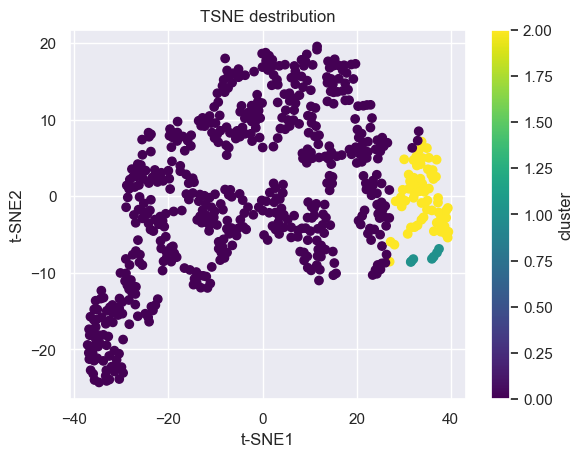

In [157]:
from sklearn.manifold import TSNE
tsne = TSNE(n_components = 2,
           random_state = 42,
           perplexity =30,
           learning_rate = "auto")

X_tsne = tsne.fit_transform(X_scaled)
plt.scatter(
     X_tsne[:, 0],
     X_tsne[:, 1],
    c = df["Clusters"],
    cmap = "viridis")
plt.xlabel("t-SNE1")
plt.ylabel("t-SNE2")
plt.title("TSNE destribution")
plt.colorbar(label =("cluster"))
plt.show()

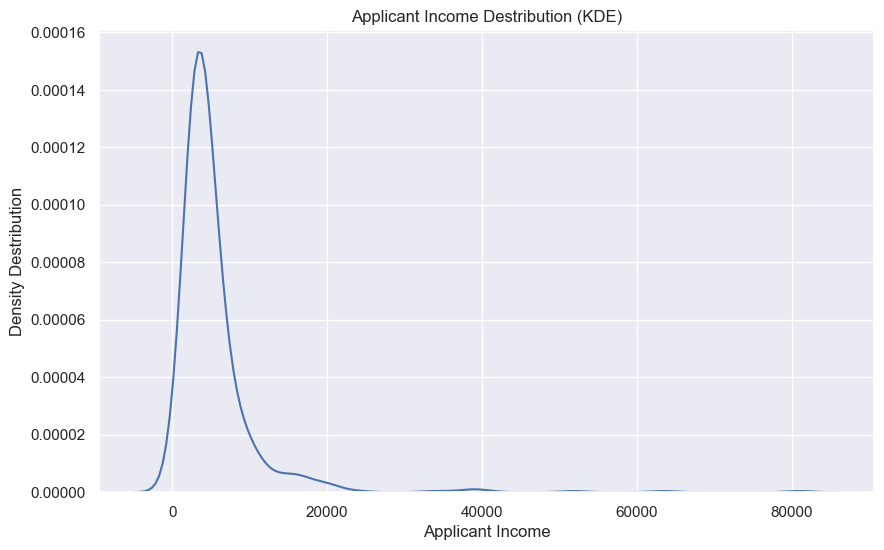

In [158]:
plt.figure(figsize = (10,6))
sns.set(style ="darkgrid")
sns.kdeplot(df["ApplicantIncome"])
plt.title("Applicant Income Destribution (KDE)")
plt.xlabel("Applicant Income")
plt.ylabel("Density Destribution")
plt.show()

SUPERVISED MACHINE LEARNING

In [159]:
df.head(5)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Clusters,Dbscan,PCA1,PCA2,Gaussian,AgglomerativeClustering
0,LP001002,Male,No,0.0,Graduate,No,5849,0.0,146.412162,360.0,1.0,Urban,Y,0,0,0.051612,0.051612,1,1
1,LP001003,Male,Yes,1.0,Graduate,No,4583,1508.0,128.000000,360.0,1.0,Rural,N,0,0,-0.250093,0.060006,1,1
2,LP001005,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.000000,360.0,1.0,Urban,Y,0,0,-0.955576,0.398733,1,1
3,LP001006,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.000000,360.0,1.0,Urban,Y,0,0,-0.549146,-0.104309,1,1
4,LP001008,Male,No,0.0,Graduate,No,6000,0.0,141.000000,360.0,1.0,Urban,Y,0,0,0.023528,0.114681,1,1


In [160]:
df.shape

(614, 19)

In [161]:
pd.set_option("display.max_rows", 614)

In [162]:
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Clusters,Dbscan,PCA1,PCA2,Gaussian,AgglomerativeClustering
0,LP001002,Male,No,0.0,Graduate,No,5849,0.000000,146.412162,360.0,1.0,Urban,Y,0,0,0.051612,0.051612,1,1
1,LP001003,Male,Yes,1.0,Graduate,No,4583,1508.000000,128.000000,360.0,1.0,Rural,N,0,0,-0.250093,0.060006,1,1
2,LP001005,Male,Yes,0.0,Graduate,Yes,3000,0.000000,66.000000,360.0,1.0,Urban,Y,0,0,-0.955576,0.398733,1,1
3,LP001006,Male,Yes,0.0,Not Graduate,No,2583,2358.000000,120.000000,360.0,1.0,Urban,Y,0,0,-0.549146,-0.104309,1,1
4,LP001008,Male,No,0.0,Graduate,No,6000,0.000000,141.000000,360.0,1.0,Urban,Y,0,0,0.023528,0.114681,1,1
5,LP001011,Male,Yes,2.0,Graduate,Yes,5417,4196.000000,267.000000,360.0,1.0,Urban,Y,2,0,1.017044,-1.013907,0,0
6,LP001013,Male,Yes,0.0,Not Graduate,No,2333,1516.000000,95.000000,360.0,1.0,Urban,Y,0,0,-0.788632,0.077256,1,1
7,LP001014,Male,Yes,3.0,Graduate,No,3036,2504.000000,158.000000,360.0,0.0,Semiurban,N,0,0,-0.176669,-0.371833,1,1
8,LP001018,Male,Yes,2.0,Graduate,No,4006,1526.000000,168.000000,360.0,1.0,Urban,Y,0,0,0.019908,-0.343677,1,1
9,LP001020,Male,Yes,1.0,Graduate,No,12841,10968.000000,349.000000,360.0,1.0,Semiurban,N,2,0,2.567581,-0.844422,0,0


In [163]:
pd.crosstab(df["Gender"],df["Loan_Status"])

Loan_Status,N,Y
Gender,,
Female,37,75
Male,155,347


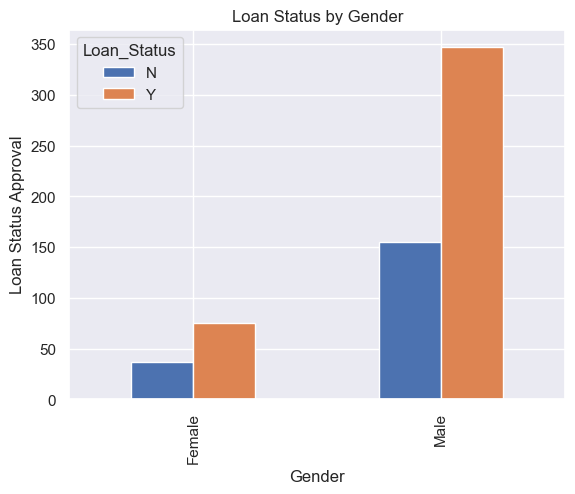

In [164]:
pd.crosstab(df["Gender"],df["Loan_Status"]).plot(kind ="bar")
plt.title("Loan Status by Gender")
plt.xlabel("Gender")
plt.ylabel("Loan Status Approval")
plt.show()

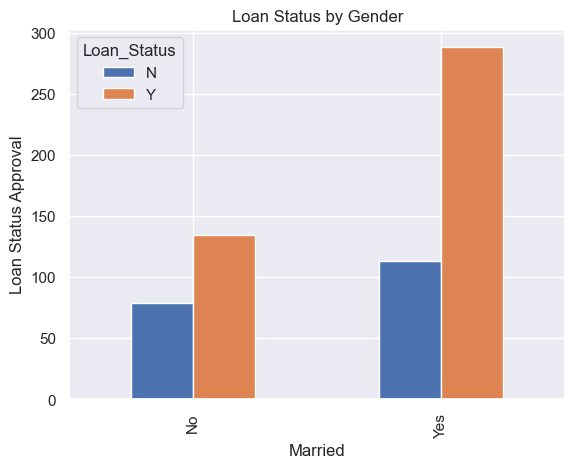

In [165]:
pd.crosstab(df["Married"],df["Loan_Status"]).plot(kind ="bar")
plt.title("Loan Status by Gender")
plt.xlabel("Married")
plt.ylabel("Loan Status Approval")
plt.show()

In [166]:
pd.crosstab(df["Gender"],df["Property_Area"])

Property_Area,Rural,Semiurban,Urban
Gender,,,
Female,24,55,33
Male,155,178,169


Axes(0.125,0.11;0.775x0.77)


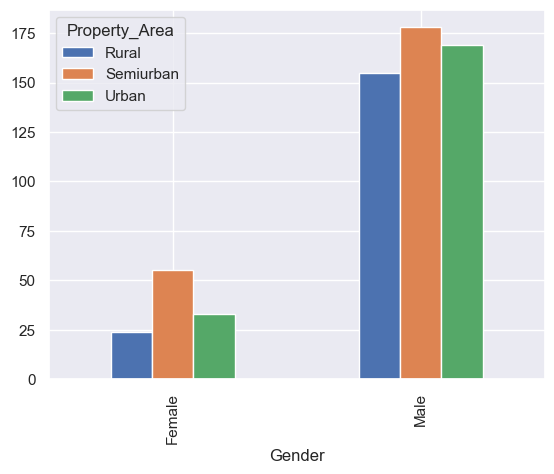

In [167]:

data=pd.crosstab(df["Gender"],df["Property_Area"]).plot(kind="bar")
print(data)

In [168]:
corr=df.corr(numeric_only =True)
corr

,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Clusters,Dbscan,PCA1,PCA2,Gaussian,AgglomerativeClustering
Dependents,1.000000,0.118202,0.030430,0.163106,-0.101054,-0.040160,0.099550,-0.038460,1.589728e-01,-4.817618e-02,-0.022078,-0.043292
ApplicantIncome,0.118202,1.000000,-0.116605,0.565620,-0.045242,-0.018615,0.428998,0.126270,8.847656e-01,4.660362e-01,0.017392,-0.149760
CoapplicantIncome,0.030430,-0.116605,1.000000,0.187828,-0.059675,0.011134,0.120739,0.048556,4.025010e-02,-3.266194e-01,-0.042112,-0.091989
LoanAmount,0.163106,0.565620,0.187828,1.000000,0.038801,-0.001431,0.725340,0.359574,8.847656e-01,-4.660362e-01,-0.036339,-0.471165
Loan_Amount_Term,-0.101054,-0.045242,-0.059675,0.038801,1.000000,0.000432,0.035727,0.036206,-3.639578e-03,-9.016820e-02,0.028915,-0.032832
Credit_History,-0.040160,-0.018615,0.011134,-0.001431,0.000432,1.000000,0.037951,0.009733,-1.132841e-02,-1.843719e-02,-0.038000,-0.081336
Clusters,0.099550,0.428998,0.120739,0.725340,0.035727,0.037951,1.000000,0.302108,6.523414e-01,-3.179394e-01,-0.272731,-0.643596
Dbscan,-0.038460,0.126270,0.048556,0.359574,0.036206,0.009733,0.302108,1.000000,2.745608e-01,-2.503073e-01,0.149823,-0.231475
PCA1,0.158973,0.884766,0.040250,0.884766,-0.003640,-0.011328,0.652341,0.274561,1.000000e+00,4.044019e-17,-0.010707,-0.350898
PCA2,-0.048176,0.466036,-0.326619,-0.466036,-0.090168,-0.018437,-0.317939,-0.250307,4.044019e-17,1.000000e+00,0.057647,0.344829


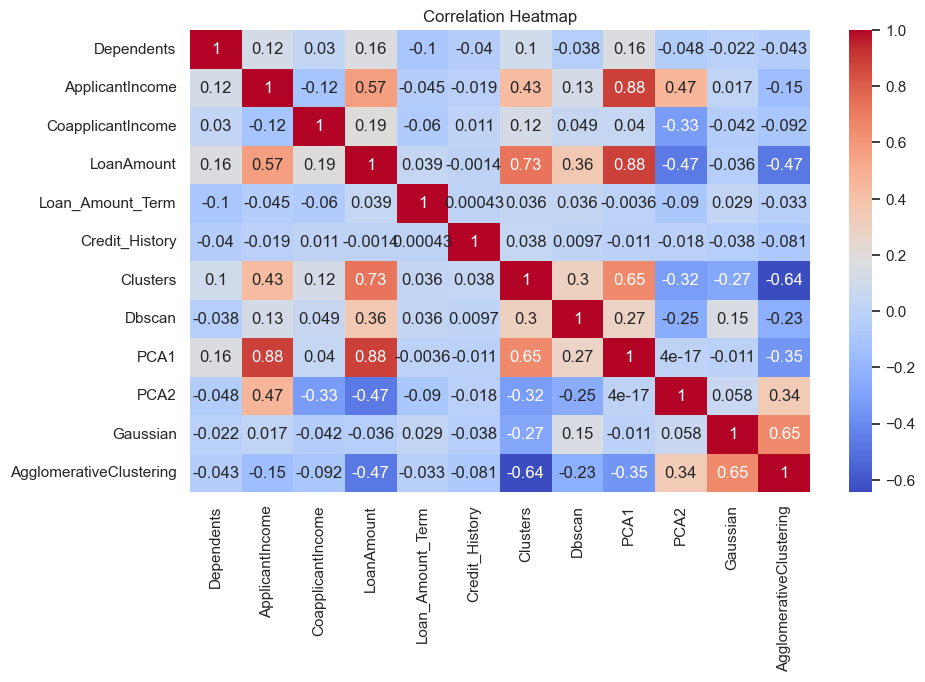

In [169]:
plt.figure(figsize=(10,6))

corr = df.corr(numeric_only=True)

sns.heatmap(corr,
            annot=True,
            cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

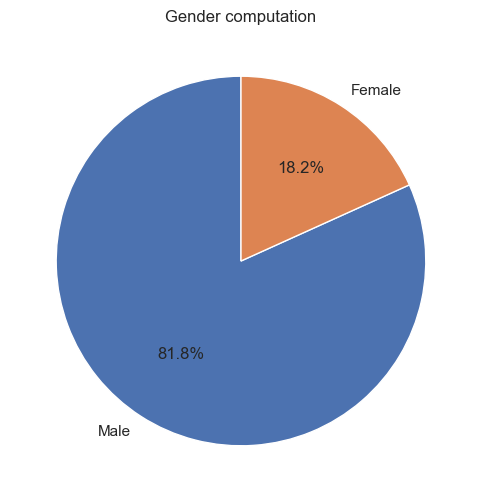

In [170]:
plt.figure(figsize=(6,6))
df["Gender"].value_counts().plot(
    kind ="pie",
    autopct ="%1.1f%%",
    startangle =90
)
plt.title("Gender computation")
plt.ylabel("")
plt.show()
    

In [171]:
df["Loan_Status"] = df["Loan_Status"].replace({
    "Y": 1,
    "N": 0,
})

C:\Users\User\AppData\Local\Temp\ipykernel_24468\1406774178.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Loan_Status"] = df["Loan_Status"].replace({


In [172]:
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Clusters,Dbscan,PCA1,PCA2,Gaussian,AgglomerativeClustering
0,LP001002,Male,No,0.0,Graduate,No,5849,0.000000,146.412162,360.0,1.0,Urban,1,0,0,0.051612,0.051612,1,1
1,LP001003,Male,Yes,1.0,Graduate,No,4583,1508.000000,128.000000,360.0,1.0,Rural,0,0,0,-0.250093,0.060006,1,1
2,LP001005,Male,Yes,0.0,Graduate,Yes,3000,0.000000,66.000000,360.0,1.0,Urban,1,0,0,-0.955576,0.398733,1,1
3,LP001006,Male,Yes,0.0,Not Graduate,No,2583,2358.000000,120.000000,360.0,1.0,Urban,1,0,0,-0.549146,-0.104309,1,1
4,LP001008,Male,No,0.0,Graduate,No,6000,0.000000,141.000000,360.0,1.0,Urban,1,0,0,0.023528,0.114681,1,1
5,LP001011,Male,Yes,2.0,Graduate,Yes,5417,4196.000000,267.000000,360.0,1.0,Urban,1,2,0,1.017044,-1.013907,0,0
6,LP001013,Male,Yes,0.0,Not Graduate,No,2333,1516.000000,95.000000,360.0,1.0,Urban,1,0,0,-0.788632,0.077256,1,1
7,LP001014,Male,Yes,3.0,Graduate,No,3036,2504.000000,158.000000,360.0,0.0,Semiurban,0,0,0,-0.176669,-0.371833,1,1
8,LP001018,Male,Yes,2.0,Graduate,No,4006,1526.000000,168.000000,360.0,1.0,Urban,1,0,0,0.019908,-0.343677,1,1
9,LP001020,Male,Yes,1.0,Graduate,No,12841,10968.000000,349.000000,360.0,1.0,Semiurban,0,2,0,2.567581,-0.844422,0,0


# SUPERVISED MACHINE  LEARNING  MODEL
```pyhon
1.Logistics Regression
2.Linear Regression
3.Naive Bayes (GaussianNB) destribution
4.Random Forest Classifiers
5.SVC (Surpot Vector Machine)
6. Xgboost Classifiers
7.Decission Tree Classifiers
```
### NB 
-We will take the most performed machine learning model with the highest accuracy score to make the final predictions

In [173]:
X =df[["ApplicantIncome","CoapplicantIncome","LoanAmount","Loan_Amount_Term","Credit_History"]] # feature variables
y =df["Loan_Status"] # target Variabe(either approved or rejected)


In [174]:
X.shape

(614, 5)

In [175]:
y

0      1
1      0
2      1
3      1
4      1
5      1
6      1
7      0
8      1
9      0
10     1
11     1
12     1
13     0
14     1
15     1
16     1
17     0
18     0
19     1
20     0
21     1
22     0
23     0
24     0
25     1
26     1
27     1
28     0
29     1
30     0
31     0
32     0
33     1
34     0
35     1
36     0
37     1
38     1
39     1
40     0
41     1
42     1
43     1
44     1
45     1
46     1
47     1
48     0
49     1
50     1
51     1
52     0
53     0
54     0
55     1
56     1
57     0
58     1
59     1
60     1
61     1
62     0
63     0
64     0
65     0
66     0
67     1
68     1
69     0
70     1
71     1
72     1
73     0
74     1
75     0
76     0
77     0
78     0
79     1
80     1
81     1
82     0
83     0
84     1
85     1
86     1
87     1
88     1
89     1
90     1
91     1
92     1
93     1
94     1
95     0
96     1
97     1
98     1
99     1
100    1
101    1
102    1
103    1
104    1
105    1
106    1
107    0
108    0
109    1
110    1
1

In [176]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test =train_test_split(X,
                                               y,
                                               test_size = 0.2,
                                               random_state = 42) 


In [177]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler() 
X_trained_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [178]:
X_test_scaled

array([[ 6.04084831e-01, -5.28127061e-01,  9.20698112e-01,
         2.94492056e-01,  4.07763147e-01],
       [-2.01225648e-01, -5.28127061e-01, -2.16350571e-01,
         2.94492056e-01,  4.07763147e-01],
       [-2.25352905e-01, -7.22934567e-02,  1.08520481e-01,
         2.94492056e-01,  4.07763147e-01],
       [-4.39123777e-01, -5.28127061e-01, -9.00900289e-01,
         2.94492056e-01,  4.07763147e-01],
       [-4.69831196e-01, -5.28127061e-01, -9.12502826e-01,
         2.94492056e-01,  4.07763147e-01],
       [-6.27755061e-01,  1.74997061e-01, -4.83208936e-01,
         2.94492056e-01,  4.07763147e-01],
       [-3.01277840e-01, -5.28127061e-01, -3.32375947e-01,
         2.94492056e-01,  4.07763147e-01],
       [-4.22251570e-01, -5.28127061e-01, -9.58912976e-01,
         2.94492056e-01,  4.07763147e-01],
       [-4.81810463e-01, -2.81906892e-02,  2.82558545e-01,
         2.94492056e-01,  4.07763147e-01],
       [-7.59695726e-01,  4.23862678e-01, -4.48401323e-01,
         2.94492056e-01

In [179]:
X_trained_scaled

array([[ 0.08391466,  0.18066742,  1.349992  ,  0.29449206,  0.40776315],
       [-0.4293379 ,  0.38543027, -0.20474803,  0.29449206,  0.40776315],
       [ 0.12609518,  0.00583145,  0.71185244,  0.29449206,  0.40776315],
       ...,
       [-0.38226444, -0.52812706, -1.37660433,  0.29449206,  0.40776315],
       [ 0.76673291, -0.52812706, -0.02592784, -1.50172657,  0.40776315],
       [ 1.37463856, -0.52812706, -0.02592784,  0.29449206,  0.40776315]],
      shape=(491, 5))

In [180]:
from sklearn.linear_model import LogisticRegression # import the logistic regression from the sklearn library
model = LogisticRegression() # creating the model
model.fit(X_trained_scaled,y_train) # training the model
predictions = model.predict(X_test_scaled) # make predictions


In [181]:
predictions

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [182]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test,predictions)

In [183]:
print(f"The accuracy Score of Logistic Regresion is : {accuracy}")

The accuracy Score of Logistic Regresion is : 0.7886178861788617


In [184]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,r2_score,classification_report
cm = confusion_matrix(y_test,predictions)

print(cm)


[[18 25]
 [ 1 79]]


In [185]:
r2_score(y_test,predictions)

0.0703488372093023

In [186]:
classification_report(y_test,predictions)

'              precision    recall  f1-score   support\n\n           0       0.95      0.42      0.58        43\n           1       0.76      0.99      0.86        80\n\n    accuracy                           0.79       123\n   macro avg       0.85      0.70      0.72       123\nweighted avg       0.83      0.79      0.76       123\n'

In [187]:
from sklearn.ensemble import RandomForestClassifier 
rf  = RandomForestClassifier (random_state =42,n_estimators = 100,max_depth = 5,min_samples_split = 2)
rf.fit(X_trained_scaled,y_train)
new_pred = rf.predict(X_test_scaled)
new_pred

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [188]:
rf_score = accuracy_score(y_test,new_pred)
print(f"The accuracy Score of Random Forest Classifier is: {rf_score}")

The accuracy Score of Random Forest Classifier is: 0.7804878048780488


In [189]:
from boruta import BorutaPy
boruta =  BorutaPy(estimator = rf,
                  n_estimators = 100,
                  random_state = 42)
boruta.fit(X_trained_scaled,y_train.values)

data = {
    "Feature" : X.columns,
    "Ranking" : boruta.ranking_,
    "Accepted" :boruta.support_,
    "Rejected" :~boruta.support_,
    "Tentative":boruta.support_weak_
}
data = pd.DataFrame(data)
print(data)

             Feature  Ranking  Accepted  Rejected  Tentative
0    ApplicantIncome        3     False      True      False
1  CoapplicantIncome        3     False      True      False
2         LoanAmount        2     False      True      False
3   Loan_Amount_Term        5     False      True      False
4     Credit_History        1      True     False      False


In [190]:
data.sort_values("Ranking")

,Feature,Ranking,Accepted,Rejected,Tentative
4,Credit_History,1,True,False,False
2,LoanAmount,2,False,True,False
0,ApplicantIncome,3,False,True,False
1,CoapplicantIncome,3,False,True,False
3,Loan_Amount_Term,5,False,True,False


In [191]:
from sklearn.naive_bayes import GaussianNB
gaussian =GaussianNB()
gaussian.fit(X_trained_scaled,y_train)

new_pred_gaussian = gaussian.predict(X_test_scaled)
new_pred_gaussian




array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0])

In [192]:
accuracy_score1 = accuracy_score(y_test,new_pred_gaussian)

In [193]:
print(f"The accuracy Score for Naive Bayes is : {accuracy_score1:.5f}")

The accuracy Score for Naive Bayes is : 0.78862


In [194]:
from sklearn.svm import SVC
svm = SVC(gamma = "scale",C = 0.1,random_state = 42)
svm.fit(X_trained_scaled,y_train)
svm_predict = svm.predict(X_test_scaled)
svm_predict

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [195]:
svm_accuracy2 = accuracy_score(y_test,svm_predict)

In [196]:
print(f"The accuracy Score of Support Vector Machine is : {svm_accuracy2:.5f}")

The accuracy Score of Support Vector Machine is : 0.79675


In [197]:
from sklearn.linear_model import LinearRegression
log = LinearRegression()
log.fit(X_trained_scaled,y_train)
log_pred = log.predict(X_test_scaled)
log_pred


array([0.79591744, 0.81642079, 0.79836502, 0.82865846, 0.82887734,
       0.80235138, 0.81852066, 0.82967962, 0.79419932, 0.79507198,
       0.11516235, 0.79317468, 0.81777628, 0.79957328, 0.79536351,
       0.79781697, 0.83115721, 0.77969203, 0.79931704, 0.82782177,
       0.80362889, 0.76337972, 0.81083045, 0.8018368 , 0.83428283,
       0.77251047, 0.79566714, 0.81710256, 0.81903445, 0.83464518,
       0.82288875, 0.78458073, 0.80678294, 0.79731722, 0.78229832,
       0.08505295, 0.78577025, 0.81673109, 0.81339905, 0.79302497,
       0.81511369, 0.79551535, 0.81086584, 0.80349868, 0.81169919,
       0.81768341, 0.77317372, 0.09115884, 0.08466153, 0.10878614,
       0.79107657, 0.79873048, 0.08612097, 0.82368576, 0.78178513,
       0.82006464, 0.76660035, 0.79354326, 0.08379787, 0.80083268,
       0.00371977, 0.7872668 , 0.09973847, 0.81456984, 0.80809796,
       0.81095038, 0.80080197, 0.80543765, 0.82375721, 0.81012525,
       0.11365211, 0.81573583, 0.81900293, 0.78733876, 0.05896

In [198]:
from sklearn.tree import DecisionTreeClassifier

In [199]:
decision_model = DecisionTreeClassifier()

decision_model.fit(X_trained_scaled,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [200]:
y_decision_pred = decision_model.predict(X_test_scaled)
print(y_decision_pred)

[0 0 1 1 1 1 1 1 1 1 0 0 1 1 1 0 1 1 1 0 1 1 0 1 1 1 1 0 1 1 1 0 1 1 1 0 0
 1 1 1 1 1 1 1 1 1 1 0 0 0 1 1 0 1 1 0 1 0 0 0 0 1 0 1 1 1 1 1 1 1 0 0 1 1
 0 0 1 0 0 0 0 1 0 0 1 1 1 0 1 1 1 0 0 1 1 1 0 1 0 0 1 1 1 1 1 0 1 0 1 1 1
 0 1 1 0 1 1 1 1 1 0 1 0]


In [201]:
accuracy_pred = accuracy_score(y_test,y_decision_pred)
print(f"The accuracy Score of Decision Tree Classifier : {accuracy_pred}")

The accuracy Score of Decision Tree Classifier : 0.7073170731707317


In [202]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = 100)
knn.fit(X_trained_scaled,y_train)



,n_neighbors,100
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [203]:
knn_pred = knn.predict(X_test_scaled)
knn_pred 

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [204]:
knn_pred_accuracy = accuracy_score(y_test,knn_pred)
print(f"The accuracy Score of KNeighbors Classifier : {knn_pred_accuracy}")

The accuracy Score of KNeighbors Classifier : 0.7967479674796748


In [205]:
!pip install xgboost

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [206]:
print("::::::::::Total Accuracy Score of Suppervised Machine Learning used::::::::::::::::::::::::::::::::::::::::::")
print(f"The accuracy Score of Logistic Regresion is      : {accuracy}")
print(f"The accuracy Score of Random Forest Classifier is: {rf_score}")
print(f"The accuracy Score for Naive Bayes is            : {accuracy_score1}")
print(f"The accuracy Score of Support Vector Machine is  : {svm_accuracy2}")
print(f"The accuracy Score of KNeighbors Classifier : {knn_pred_accuracy}")

::::::::::Total Accuracy Score of Suppervised Machine Learning used::::::::::::::::::::::::::::::::::::::::::
The accuracy Score of Logistic Regresion is      : 0.7886178861788617
The accuracy Score of Random Forest Classifier is: 0.7804878048780488
The accuracy Score for Naive Bayes is            : 0.7886178861788617
The accuracy Score of Support Vector Machine is  : 0.7967479674796748
The accuracy Score of KNeighbors Classifier : 0.7967479674796748


In [207]:
import pickle

In [208]:
with open("svc_clear_model.pkl", "wb") as model_file:
    pickle.dump(svm, model_file)
    print("model saved successfully!")

model saved successfully!
